In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("All Libraries imported")

All Libraries imported


In [3]:
from google.colab import files
uploaded_files = files.upload()
df = pd.read_csv("archive.zip")
print("Dataset loaded successfully!")

Saving archive.zip to archive (1).zip
Dataset loaded successfully!


In [5]:
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
print("The no. rows and columns:", df.shape)

The no. rows and columns: (7043, 21)


In [12]:
print(df.columns.tolist())
print(df.info)

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
<bound method DataFrame.info of       customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZA

In [16]:
display(df.describe())

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [17]:
print(df.isnull().sum())


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [18]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [19]:
df = df.drop_duplicates()

print("Duplicates removed successfully!")
print("New dataset shape:", df.shape)

Duplicates removed successfully!
New dataset shape: (7043, 21)


In [20]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print(df["TotalCharges"].dtype)


float64


In [21]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Missing values after cleaning:")
print(df.isnull().sum().sum())

Missing values after cleaning:
0


In [22]:
print("Final dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate records:", df.duplicated().sum())

display(df.head())

Final dataset shape: (7043, 21)
Missing values: 0
Duplicate records: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [23]:
print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


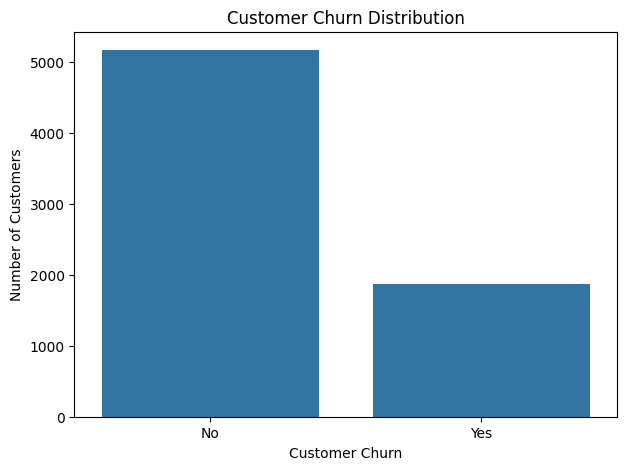

In [24]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.show()

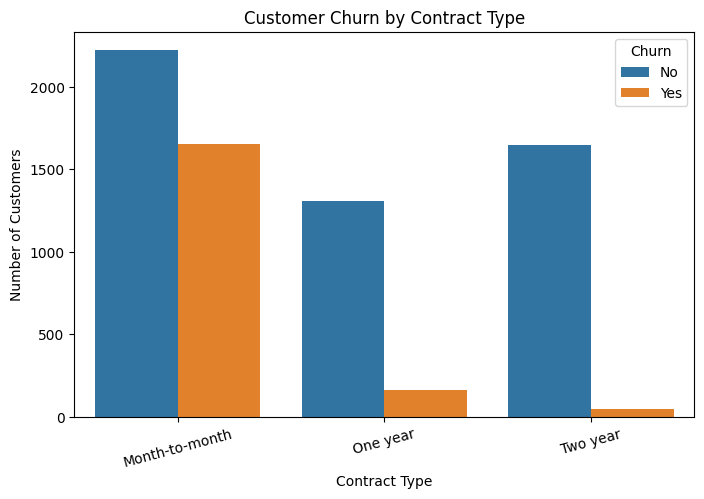

In [25]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.xticks(rotation=15)
plt.show()

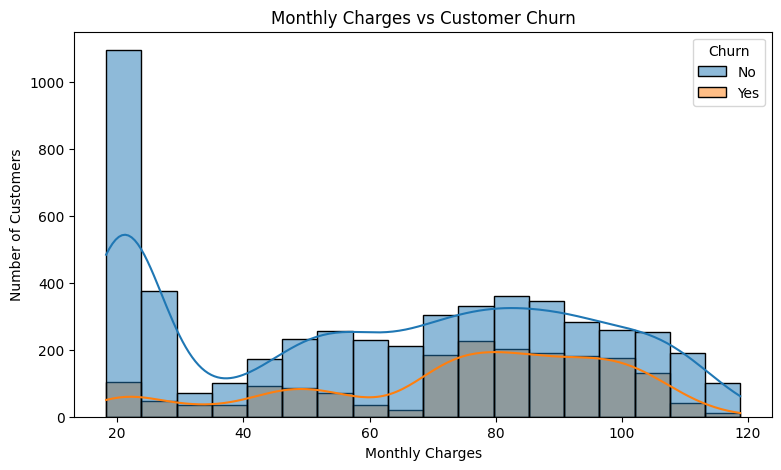

In [26]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="MonthlyCharges",
    hue="Churn",
    kde=True
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.show()

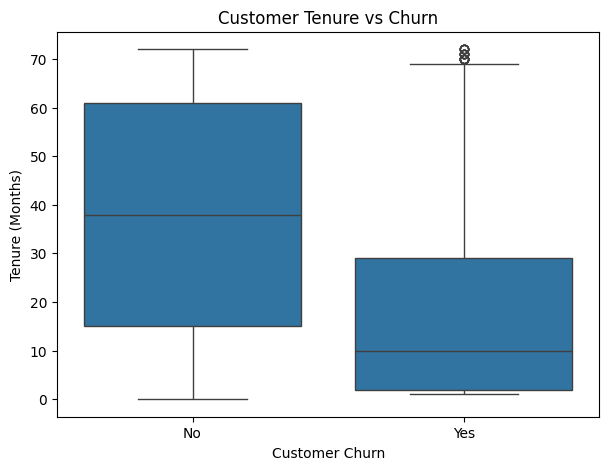

In [27]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Tenure (Months)")

plt.show()

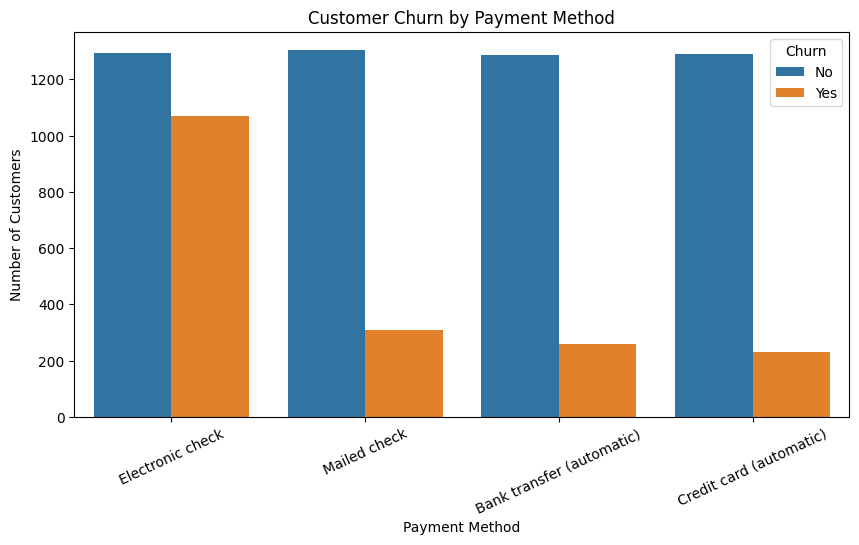

In [28]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")

plt.xticks(rotation=25)
plt.show()

In [29]:
churn_percentage = (
    df["Churn"].value_counts(normalize=True) * 100
)

print("Customer Churn Percentage:")
print(churn_percentage)

Customer Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [30]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


In [31]:
average_charges = df.groupby(
    "Churn"
)["MonthlyCharges"].mean()

print(average_charges)

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64


In [32]:
average_tenure = df.groupby(
    "Churn"
)["tenure"].mean()

print(average_tenure)

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64


In [33]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn.round(2))

Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


In [34]:
numeric_data = df.select_dtypes(
    include=np.number
)

correlation = numeric_data.corr()

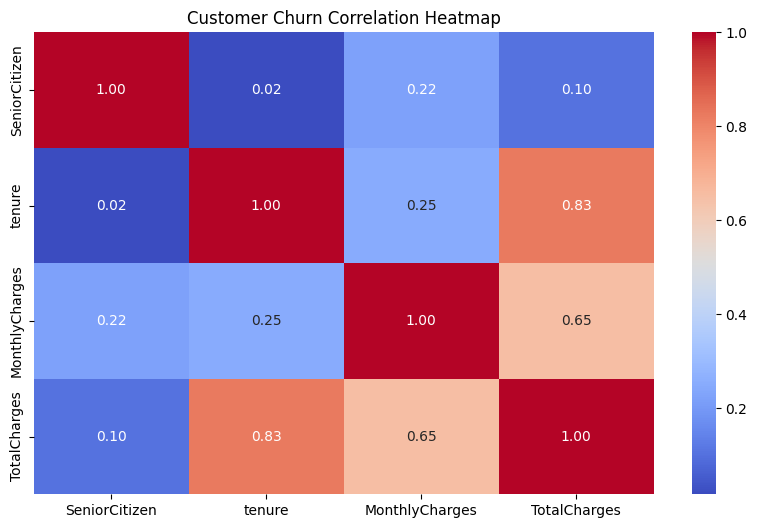

In [35]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Customer Churn Correlation Heatmap")
plt.show()

In [ ]:
# Customer Churn Analysis Using Python

## 1. Introduction
Customer churn occurs when customers stop using a company's services. This project analyzes telecom customer data to identify patterns associated with customer churn.

## 2. Objective
- Analyze customer churn behaviour.
- Identify customer groups with higher churn rates.
- Understand the relationship between customer tenure, monthly charges and churn.
- Provide data-driven customer retention recommendations.

## 3. Dataset
- Source: Kaggle – IBM Telco Customer Churn
- Total records: 7,043 (original dataset)
- Total columns: 21
- Target variable: Churn

## 4. Technologies Used
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn

## 5. Project Methodology
1. Data collection
2. Data loading
3. Data understanding
4. Data cleaning
5. Exploratory Data Analysis
6. Data visualization
7. Statistical analysis
8. Business insights

## 6. Visualizations
- Customer churn distribution
- Churn by contract type
- Monthly charges distribution
- Customer tenure analysis
- Payment method analysis
- Correlation heatmap

## 7. Key Findings
Add 3–5 findings from the actual analysis.

## 8. Conclusion
This project demonstrates how Python-based data analysis can help identify customer churn patterns and support better customer retention decisions.
